# PPMI Protein PCA

We use baseline (initial visit) CSF protein measurements to examine the variation patterns between participants.
Only proteins are used for PCA. Clinical groups (PD, healthy controls, prodromal) and source projects are used to interpret the plots.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

data_path = Path.home() / "Downloads/PPMI Proteomic Data/Project_9004_Unified_Emerging_Biomarkers_20260815.tab"
source = "harmonized_olink_csf_src"

metadata = ["PATNO", "EVENT_ID", "COHORT", source, "updrs3_score", "slope_updrs3_off"]
header = pd.read_csv(data_path, sep="\t", nrows=0).columns
proteins = [column for column in header if column.startswith("harmonized_olink_csf_") and column.endswith("_NPX")]

data = pd.read_csv(data_path, sep="\t", usecols=metadata + proteins, low_memory=False)

## Participants

In [ ]:
# Count clinical assessments across all visits.
clinical_visits = data.groupby("PATNO")["updrs3_score"].count()

csf = data[data[source].notna()].copy()
baseline = csf[csf["EVENT_ID"] == "BL"].copy()

cohort_names = {1: "PD", 2: "Healthy control", 4: "Prodromal"}
cohort_order = ["PD", "Healthy control", "Prodromal"]
cohort_colors = {"PD": "#31688e", "Healthy control": "#35b779", "Prodromal": "#e69f00"}
baseline["cohort"] = baseline["COHORT"].map(cohort_names)
baseline["source"] = baseline[source].map({
    "p277_CSF_corrected": "Project 277",
    "p314_CSF": "Project 314"
})

In [4]:
print("CSF visits:", len(csf))
print("Participants with CSF:", csf["PATNO"].nunique())
print("Baseline participants:", baseline["PATNO"].nunique())

counts = pd.DataFrame({
    "Any CSF visit": csf.groupby("COHORT")["PATNO"].nunique(),
    "Baseline CSF": baseline.groupby("COHORT")["PATNO"].nunique()
})
counts.rename(index=cohort_names).reindex(cohort_order)

CSF visits: 3235
Participants with CSF: 2239
Baseline participants: 2199


,Any CSF visit,Baseline CSF
COHORT,,
PD,956,938
Healthy control,256,245
Prodromal,1027,1016


In [6]:
csf_visits = csf.groupby("PATNO").size()
print("Participants with one CSF visit:", (csf_visits == 1).sum())
print("Percentage:", round((csf_visits == 1).mean() * 100, 1))

Participants with one CSF visit: 1484
Percentage: 66.3


## Preprocessing

Remove proteins with more than 20% missing values, fill remaining gaps with each protein's median, and standardize each protein to mean 0 and standard deviation 1.
The supplied measurements are normalized log2 NPX values. The standardization here puts proteins on comparable scales for PCA.

In [8]:
missing_fraction = baseline[proteins].isna().mean()
retained_proteins = missing_fraction[missing_fraction <= 0.20].index
protein_data = baseline[retained_proteins]

print("Available proteins:", len(proteins))
print("Removed proteins with more than 20% missing values:", len(proteins) - len(retained_proteins))
print("Total proteins left for analysis:", len(retained_proteins))
print("Values filled with median (%):", round(protein_data.isna().mean().mean() * 100, 2))

imputed_proteins = SimpleImputer(strategy="median").fit_transform(protein_data)
standardized_proteins = StandardScaler().fit_transform(imputed_proteins)

Available proteins: 5416
Removed proteins with more than 20% missing values: 24
Total proteins left for analysis: 5392
Values filled with median (%): 1.04


## PCA

Variance explained measures how much protein variation each principal component captures.

In [9]:
pc_names = ["PC1", "PC2", "PC3"]
pca = PCA(n_components=3, svd_solver="full")
baseline[pc_names] = pca.fit_transform(standardized_proteins)
variance = pca.explained_variance_ratio_ * 100

pd.DataFrame({
    "Variance explained (%)": variance,
    "Cumulative variance explained (%)": variance.cumsum()
}, index=pc_names).round(2)

,Variance explained (%),Cumulative variance explained (%)
PC1,16.70,16.70
PC2,4.97,21.67
PC3,1.56,23.23


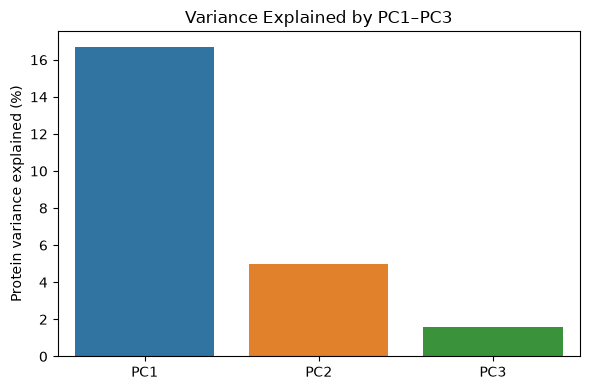

In [16]:
plt.figure(figsize=(6, 4))
sns.barplot(x=pc_names, y=variance, hue=pc_names)
plt.ylabel("Protein variance explained (%)")
plt.title("Variance Explained by PC1–PC3")
plt.tight_layout()
plt.show()

## PCA by clinical group

Each dot is one baseline participant. Overlap in these components does not rule out predictive information in individual proteins or other combinations.

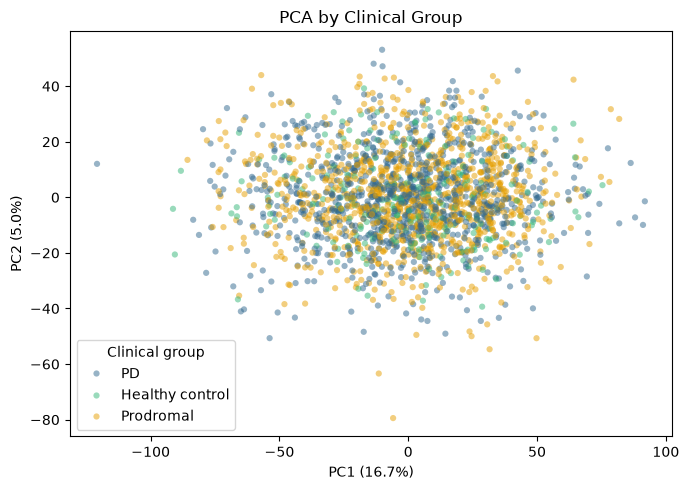

In [33]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=baseline, x="PC1", y="PC2", hue="cohort",
                hue_order=cohort_order, palette=cohort_colors, s=20, alpha=0.5, linewidth=0)
plt.xlabel(f"PC1 ({variance[0]:.1f}%)")
plt.ylabel(f"PC2 ({variance[1]:.1f}%)")
plt.title("PCA by Clinical Group")
plt.legend(title="Clinical group")
plt.tight_layout()
plt.show()

## PCA by source project

Projects 277 and 314 supplied the CSF measurements. Both Project 277 to the Project 314 were adjusted to the same scale in the original dataset.
This plot examines separation based on the source project (batch effects).

In [29]:
pd.crosstab(baseline["cohort"], baseline["source"]).reindex(cohort_order)

source,Project 277,Project 314
cohort,,
PD,244,694
Healthy control,122,123
Prodromal,340,676


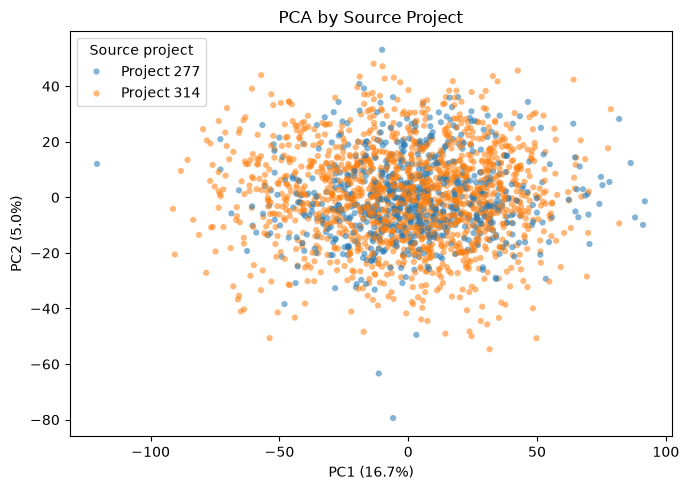

In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=baseline, x="PC1", y="PC2", hue="source",
                s=20, alpha=0.55, linewidth=0)
plt.xlabel(f"PC1 ({variance[0]:.1f}%)")
plt.ylabel(f"PC2 ({variance[1]:.1f}%)")
plt.title("PCA by Source Project")
plt.legend(title="Source project")
plt.tight_layout()
plt.show()

## Project 314 only

Repeat preprocessing and PCA within one source project to check whether the group-overlap result persists.

In [37]:
project314 = baseline[baseline[source] == "p314_CSF"].copy()
missing314 = project314[proteins].isna().mean()
proteins314 = missing314[missing314 <= 0.20].index

imputed314 = SimpleImputer(strategy="median").fit_transform(project314[proteins314])
standardized314 = StandardScaler().fit_transform(imputed314)
pca314 = PCA(n_components=3, svd_solver="full")
project314[pc_names] = pca314.fit_transform(standardized314)
variance314 = pca314.explained_variance_ratio_ * 100

print("Project 314 participants:", len(project314))

Project 314 participants: 1493


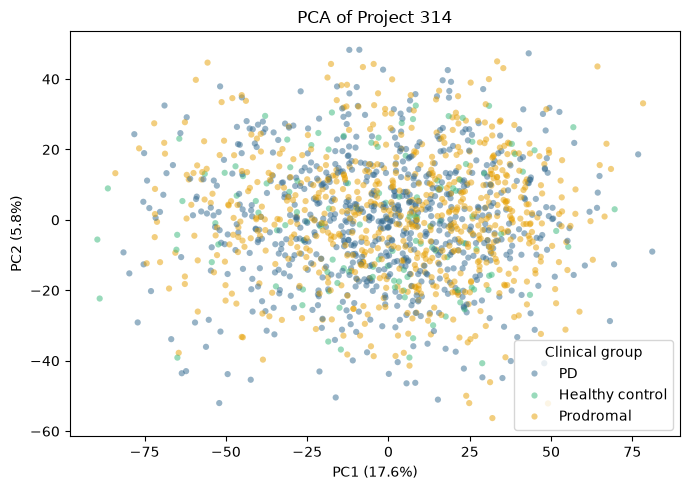

In [41]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=project314, x="PC1", y="PC2", hue="cohort",
                hue_order=cohort_order, palette=cohort_colors, s=20, alpha=0.5, linewidth=0)
plt.xlabel(f"PC1 ({variance314[0]:.1f}%)")
plt.ylabel(f"PC2 ({variance314[1]:.1f}%)")
plt.title("PCA of Project 314")
plt.legend(title="Clinical group")
plt.tight_layout()
plt.show()

## Clinical progression

The slope estimates annual change in the motor score (UPDRS 3, OFF medication or untreated).
We correlate baseline principal components with this slope in PD participants.

In [51]:
pd_baseline = baseline[baseline["COHORT"] == 1].copy()
has_slope = pd_baseline["slope_updrs3_off"].notna()
progression = pd_baseline[has_slope]

print("PD participants with baseline proteins:", len(pd_baseline))
print("With a progression slope (more than one visit):", has_slope.sum())

correlations = progression[pc_names].corrwith(progression["slope_updrs3_off"], method="spearman")
correlations.rename("Spearman correlation with progression").round(3).to_frame()

PD participants with baseline proteins: 938
With a progression slope (more than one visit): 819


,Spearman correlation with progression
PC1,-0.037
PC2,0.023
PC3,0.043


## Findings

- PC1 and PC2 capture 21.7% of protein variation. Including PC3, they capture 23.2%.
- Clinical groups and source projects overlap in the PCA plots. 
- When looking only at Project 314, the overlap of clinical groups persists.
- The PCs have weak correlations with progression (`slope_updrs3_off`). 
- We have not tested performance on prediction yet.